In [1]:
# coding=utf-8
import numpy as np
import pandas as pd
import seaborn as sns
from time import time
from operator import add 
from functools import reduce
import matplotlib.pyplot as plt
from numpy.random import uniform
from lib.bandits import Bernoulli, Gaussian
from lib.policies import p_auer, p_ape, p_unif
means = np.log(np.array([[1.3424e+04, 9.5000e+02, 9.5800e+01],
        [1.0862e+04, 7.6600e+02, 5.6600e+01],
        [8.5500e+03, 6.0600e+02, 3.5300e+01],
        [2.7242e+04, 1.7890e+03, 8.3800e+01],
        [2.3082e+04, 1.3390e+03, 7.8400e+01],
        [4.2040e+03, 2.8900e+02, 3.3500e+01],
        [3.7210e+03, 2.3400e+02, 3.8100e+01],
        [1.7079e+04, 1.4410e+03, 1.1100e+02],
        [3.3768e+04, 2.0190e+03, 1.1200e+02],
        [7.6130e+03, 4.8700e+02, 4.6700e+01],
        [2.4570e+03, 1.9300e+02, 5.3000e+01],
        [6.9750e+03, 7.2700e+02, 1.1370e+02],
        [4.6340e+03, 4.7000e+02, 9.8400e+01],
        [2.0517e+04, 1.6210e+03, 1.1550e+02],
        [1.6045e+04, 1.3440e+03, 1.3590e+02],
        [1.8350e+03, 2.0200e+02, 5.2200e+01],
        [1.4300e+03, 1.4700e+02, 5.5500e+01],
        [5.5170e+03, 5.6300e+02, 1.0600e+02],
        [3.1111e+04, 2.3680e+03, 1.4890e+02],
        [3.9960e+03, 3.7300e+02, 4.7800e+01]]))
K = 20
D = 3
inf = 1e12
stddev = np.sqrt(np.array([0.70437039, 0.82845749, 1.53743137]))
bandit = Gaussian(means, stddev)
print("[complexity]: ", bandit.H)
print("[pareto set]: ", bandit.optimal_arms)

[complexity]:  549.6836351585227
[pareto set]:  [8, 18]


In [2]:
numiter = 2000
seeds = (np.random.uniform(size=numiter)*2**31).astype(np.uint)
delta = 0.1
eps_1 = 0.
eps_2 = 0.

In [3]:
psi_ape = p_ape(bandit)
psi_auer = p_auer(bandit)
psi_unif = p_unif(bandit)
res_psi_ape = []
mvals = [*range(1, len(bandit.optimal_arms)+2), 20]#,
for k in mvals:
    print(k)
    res_ = []
    for seed in seeds:
        __res = psi_ape.loop(seed, delta, eps_1, eps_2, k)
        res_  += [sum(__res[0][1])]
    res_psi_ape += [res_]
res_psi_auer = []
for seed in seeds:
    res_psi_auer += [sum(psi_auer.loop(seed, delta, eps_1)[0][1])]
res_psi_ape = np.array(res_psi_ape, dtype=float)
res_psi_auer  = np.array(res_psi_auer, dtype=float)
for k, m in enumerate(mvals):
    print("[m=%d] [APE]:"%m, np.mean(res_psi_ape[k], axis=0))
print("[Auer]:", np.mean(res_psi_auer))

1
2
3
20
[m=1] [APE]: 2403.797
[m=2] [APE]: 11870.617
[m=3] [APE]: 27579.365
[m=20] [APE]: 27579.365
[Auer]: 40070.219


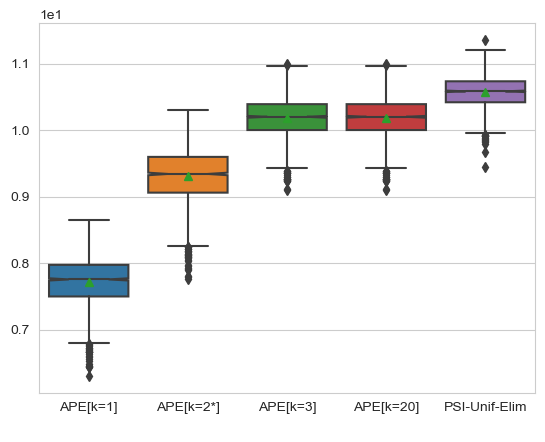

In [6]:
data = np.log(np.concatenate((*res_psi_ape, res_psi_auer))) #, res_psi_auer, res_psi_lucb
labels = [str(m) + "*"*(m==len(bandit.optimal_arms)) for m in mvals ]
df = pd.DataFrame({"sc": data, "names": reduce(add, [["APE[k=%s]"%m]*seeds.size for m in labels]) + ["PSI-Unif-Elim"]*seeds.size  }) #["Auer"]*seeds.size + ["LUCB"]*seeds.size
sns.boxplot(data=df, x="names", y="sc",  orient="v", showmeans=True, showfliers=True, notch=True).set(
    xlabel=' ',
    ylabel=r'')
plt.ticklabel_format(axis="y", style="sci", scilimits=(0,0))
np.save("log-main-all-arms-d3.npy", data)

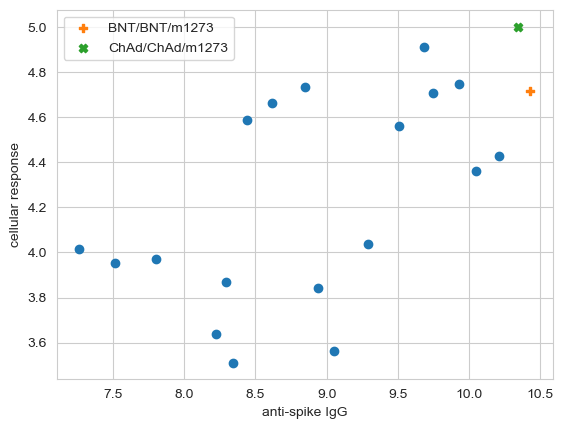

In [38]:
mask = np.ones(K, bool)
mask[bandit.optimal_arms] = False
names = ["BNT/BNT/m1273", "ChAd/ChAd/m1273"]
plt.scatter(*means[mask][:, [0, 2]].T, marker="o")
markers = ["P", "X"]
for k,v in enumerate(bandit.optimal_arms):
    plt.scatter(*means[v][[0, 2]], label="%s"%names[k], marker=markers[k])
plt.legend(frameon=True)
plt.xlabel("anti-spike IgG")
plt.ylabel("cellular response")